# 07. Sazonalidade dos diagnósticos

Há meses do ano em que mais casos de câncer de mama são diagnosticados? A pergunta tem interesse prático por causa do Outubro Rosa, a campanha anual de conscientização que aumenta a procura por mamografias em outubro. Se a campanha funciona, esperaríamos ver mais diagnósticos nos meses seguintes.

A fonte principal é o Painel de Oncologia, que tem a data de diagnóstico de todos os casos do SUS de 2013 a 2024. O RHC é usado como confirmação.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from mama import codigos as c, graficos as g
from mama.config import FONTE_PAINEL, FONTE_RHC
from mama.analises import base, sazonalidade as saz

painel = base.painel()
rhc = base.rhc()

## Como medir a sazonalidade

Contar os casos de cada mês não basta, por dois motivos. Primeiro, os meses têm durações diferentes: fevereiro tem 28 dias e pareceria ter menos casos só por isso. Segundo, o número de casos cresce de um ano para o outro, então um mês de 2024 sempre teria mais casos que o mesmo mês de 2013.

Por isso usamos um índice. Para cada mês, calculamos o número de casos por dia. Depois dividimos pela média de casos por dia daquele ano e multiplicamos por 100. Assim, o valor 100 significa um mês típico, 105 significa 5% acima do normal e 95 significa 5% abaixo. Por fim, tiramos a média do índice entre os anos. O ano de 2020 fica de fora, porque a pandemia distorceu completamente o calendário. O código está em `src/mama/analises/sazonalidade.py`.

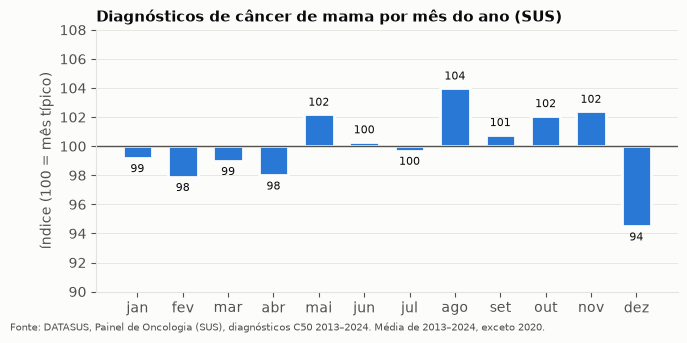

In [2]:
indice = saz.indice_mensal(painel, "ano_diagnostico", "mes_diagnostico")
base.salvar_tabela(indice, "07_indice_sazonal_brasil")
serie = indice.set_index("mes_nome").indice
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.bar(serie.index, serie.values - 100, bottom=100, color=g.AZUL, width=0.65, edgecolor=g.SUPERFICIE, linewidth=2)
ax.axhline(100, color=g.TEXTO_2, lw=1)
for i, v in enumerate(serie.values):
    ax.text(i, v + (0.4 if v >= 100 else -0.4), f"{v:.0f}", ha="center", va="bottom" if v >= 100 else "top", fontsize=8)
ax.set(title="Diagnósticos de câncer de mama por mês do ano (SUS)", ylabel="índice (100 = mês típico)", ylim=(90, 108))
ax.grid(axis="x", visible=False)
g.salvar(fig, "07_indice_sazonal_brasil", FONTE_PAINEL + " Média de 2013–2024, exceto 2020.")
plt.show()

A variação ao longo do ano é pequena. Os meses de agosto a novembro ficam entre 1% e 4% acima de um mês típico, e dezembro fica cerca de 5% abaixo. Ou seja, não existe uma estação do câncer de mama: os diagnósticos se distribuem de forma quase uniforme ao longo do ano.

O que se vê é um efeito de calendário dos serviços. Dezembro e janeiro, meses de festas e férias, têm menos diagnósticos. O período de agosto a novembro, que inclui o Outubro Rosa e as semanas seguintes (o laudo de uma biópsia sai algumas semanas depois da mamografia), tem um pouco mais. O efeito da campanha existe, mas é modesto quando medido em diagnósticos.

## Por região

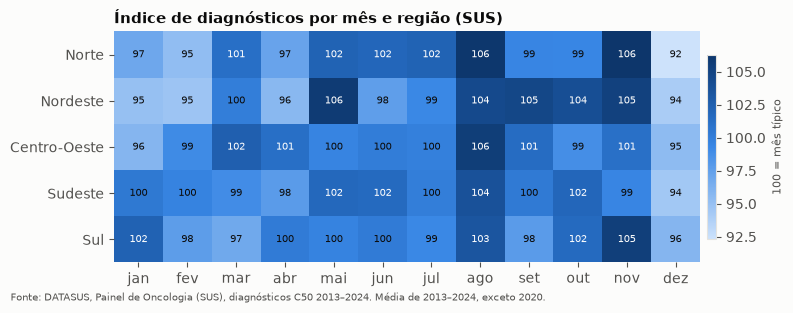

In [3]:
por_regiao = saz.indice_mensal(painel, "ano_diagnostico", "mes_diagnostico", "regiao_res")
tabela = por_regiao.pivot(index="regiao_res", columns="mes_nome", values="indice")[saz.MESES].reindex(c.REGIOES)
base.salvar_tabela(tabela, "07_indice_sazonal_regiao", index=True)
fig, ax = g.calor(tabela, "Índice de diagnósticos por mês e região (SUS)", "100 = mês típico", figsize=(9, 3))
g.salvar(fig, "07_indice_sazonal_regiao", FONTE_PAINEL + " Média de 2013–2024, exceto 2020.")
plt.show()

O padrão é parecido nas cinco regiões: dezembro é sempre o mês mais fraco, e agosto está acima da média em todas. O Nordeste e o Norte têm o maior aumento no segundo semestre, chegando a 5% ou 6% acima do normal em novembro.

## Confirmação com o RHC

O RHC organiza os casos pelo ano da primeira consulta, e não do diagnóstico. Por isso, os anos de diagnóstico das pontas (2012 e 2022) ficam incompletos e distorcem o índice. Usamos só os diagnósticos de 2014 a 2021, que estão completos.

In [4]:
x = rhc.assign(ano_diag=rhc.data_diagnostico.dt.year, mes_diag=rhc.data_diagnostico.dt.month)
x = x[x.ano_diag.between(2014, 2021)]
indice_rhc = saz.indice_mensal(x, "ano_diag", "mes_diag")
comparacao = pd.DataFrame({"Painel (SUS)": serie, "RHC (hospitais)": indice_rhc.set_index("mes_nome").indice})
base.salvar_tabela(comparacao, "07_indice_sazonal_painel_x_rhc", index=True)
comparacao.T

mes_nome,jan,fev,mar,abr,mai,jun,jul,ago,set,out,nov,dez
Painel (SUS),99.2,97.9,99.0,98.0,102.2,100.3,99.7,104.0,100.8,102.1,102.4,94.5
RHC (hospitais),89.5,97.3,99.7,97.2,101.0,101.7,101.9,105.2,101.9,102.3,104.3,98.2


As duas fontes concordam no essencial: segundo semestre um pouco acima da média e dezembro e janeiro abaixo. No RHC, janeiro é ainda mais fraco, o que é coerente com a redução de atividade dos hospitais nas férias.

## O que realmente mudou o calendário: a pandemia

O maior desvio de toda a série não é sazonal. O gráfico compara os diagnósticos de cada mês de 2019 e de 2020.

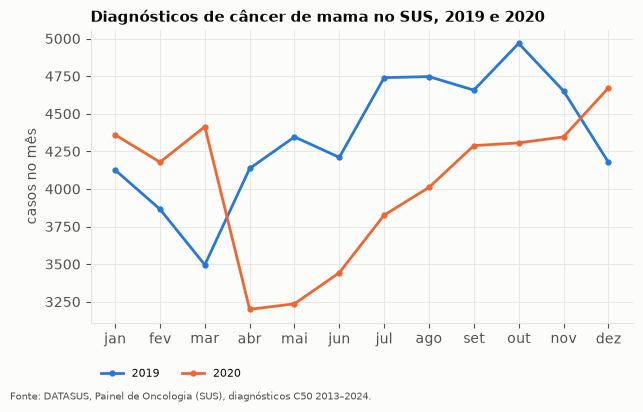

mes,1,2,3,4,5,6,7,8,9,10,11,12
ano,,,,,,,,,,,,
2019,4126,3865,3495,4136,4346,4210,4740,4747,4657,4968,4652,4178
2020,4360,4178,4414,3199,3236,3443,3826,4010,4288,4306,4346,4671


In [5]:
cont = saz.contagem_mensal(painel, "ano_diagnostico", "mes_diagnostico")
cont = cont[cont.ano_diagnostico.isin([2019, 2020])].assign(ano=lambda t: t.ano_diagnostico.astype(str),
                                                            mes=lambda t: t.mes_diagnostico.astype(int))
fig, ax = g.linhas(cont, "mes", "casos", "ano", "Diagnósticos de câncer de mama no SUS, 2019 e 2020",
                   "casos no mês", fmt="{:,.0f}", ordem=["2019", "2020"],
                   cores={"2019": g.CATEGORICAS[0], "2020": g.CATEGORICAS[1]}, rotulos_finais=False)
ax.set_xticks(range(1, 13), saz.MESES)
g.salvar(fig, "07_pandemia_2019_2020", FONTE_PAINEL)
plt.show()
cont.pivot(index="ano", columns="mes", values="casos")

Em abril de 2020, primeiro mês completo de isolamento, os diagnósticos caíram 23% em relação a abril de 2019, e ficaram abaixo do ano anterior em todos os meses até novembro. Esses casos não deixaram de existir: foram diagnosticados mais tarde, e o caderno 04 mostra que 2020 teve a maior proporção de estádio avançado da série.

## O que levar para o TCC

Não há sazonalidade relevante no diagnóstico do câncer de mama no Brasil. A variação ao longo do ano é de poucos pontos percentuais e reflete o calendário dos serviços: menos diagnósticos em dezembro e janeiro, um pouco mais no segundo semestre, em parte pelo Outubro Rosa. O resultado mais útil para o TCC é outro: interrupções no acesso, como a da pandemia, reduzem imediatamente os diagnósticos e aumentam a proporção de casos avançados nos meses seguintes.